In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [13]:
df = pd.read_csv("../data/lifestyle_disease_transformed.csv")

target = df.iloc[:4000,-1:].values
features = df.iloc[:4000,:-1].values


x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=1)

In [14]:
import heapq

class Classifier:
    def __init__(self, n_neighbors=3):
        self.n_neighbors = n_neighbors
    
    def fit(self, x_train, y_train):
        self.x_train = x_train
        self.y_train = y_train
        self.classes_ = np.unique(y_train)
    
    def distance(self, x, y):
        return np.sum((x - y) ** 2)
    
    def predict_single(self, x):
        heap = []
        
        for i in range(len(self.x_train)):
            dist = self.distance(self.x_train[i], x)

            heapq.heappush(heap, (-dist, self.y_train[i]))

            if len(heap) > self.n_neighbors:
                heapq.heappop(heap) 
        
        labels = [int(label) for (_, label) in heap]
        
        count = np.bincount(labels)
        return np.argmax(count)
    
    def predict(self, x_test):
        return np.array([self.predict_single(x) for x in x_test]).reshape(-1, 1)
    
    def _get_k_labels(self, x):
        heap = []

        for i in range(len(self.x_train)):
            dist = self.distance(self.x_train[i], x)
            heapq.heappush(heap, (-dist, self.y_train[i]))
            if len(heap) > self.n_neighbors:
                heapq.heappop(heap)

        return [int(label) for (_, label) in heap]
    
    def predict_proba(self, x_test):
        probs = []

        for x in x_test:
            labels = self._get_k_labels(x)
            count = np.bincount(labels, minlength=len(self.classes_))
            probs.append(count / self.n_neighbors)

        return np.array(probs)


In [15]:
model = Classifier(n_neighbors=3)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
y_probs_matrix = model.predict_proba(x_test)
y_probs = y_probs_matrix[:, 1]


## Model Performance Report ##
------------------------------
              Score
Accuracy   0.855000
Precision  0.782772
Recall     0.782772
F1 Score   0.782772
ROC AUC    0.909993
------------------------------


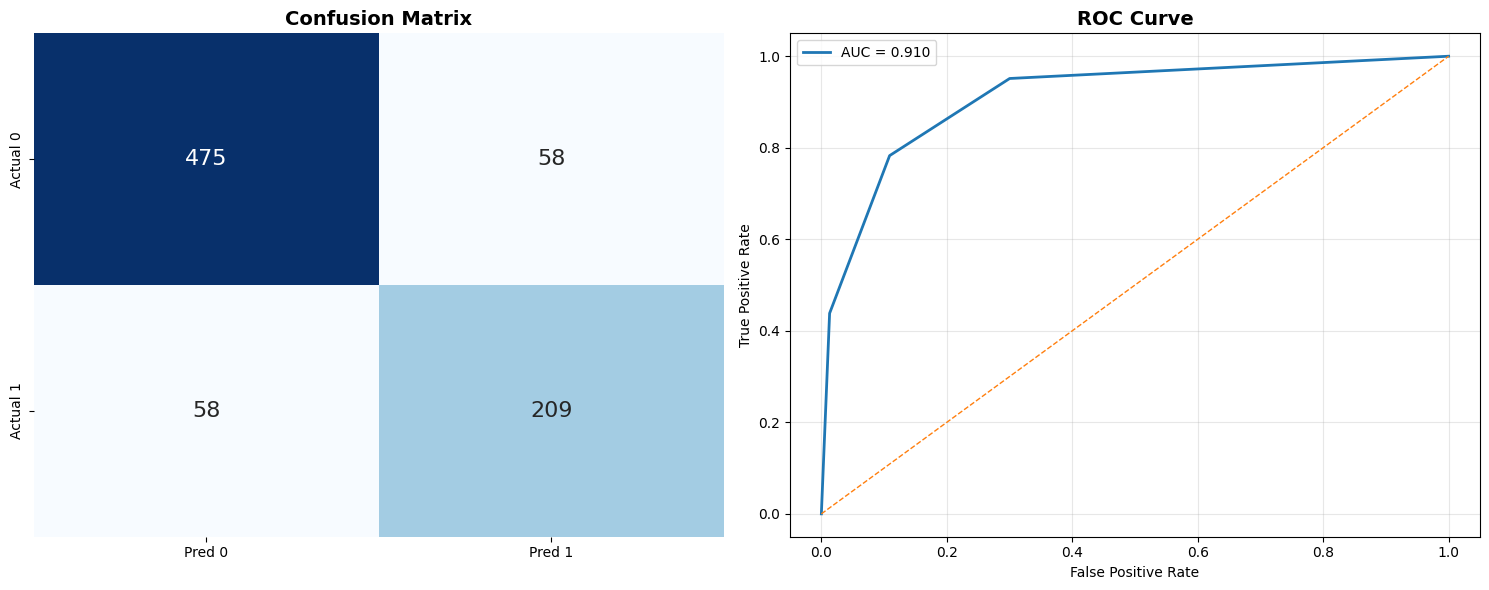

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

def report_statistical_outcomes(y_true, y_pred, y_probs=None, figsize=(15, 6)):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
    }

    if y_probs is not None:
        roc_score = roc_auc_score(y_true, y_probs)
        fpr, tpr, _ = roc_curve(y_true, y_probs)
    else:
        roc_score = roc_auc_score(y_true, y_pred)
        fpr, tpr, _ = roc_curve(y_true, y_pred)

    metrics["ROC AUC"] = roc_score

    print("## Model Performance Report ##")
    print("-" * 30)
    df_metrics = pd.DataFrame(metrics, index=[0]).T
    df_metrics.columns = ['Score']
    print(df_metrics)
    print("-" * 30)

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['Pred 0', 'Pred 1'],
        yticklabels=['Actual 0', 'Actual 1'],
        ax=axes[0], annot_kws={"size": 16}
    )
    axes[0].set_title("Confusion Matrix", fontsize=14, fontweight='bold')

    axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {roc_score:.3f}')
    axes[1].plot([0, 1], [0, 1], linestyle='--', lw=1)
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title('ROC Curve', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


report_statistical_outcomes(y_test, y_pred, y_probs)